In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8,5)

In [5]:
df = pd.read_csv("Wholesale customers data.csv")

In [6]:
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [7]:
df.tail()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


In [8]:
# Use only the six spending features (drop the categorical Channel and Region columns)
features = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# standardize the six spending features

In [9]:
print("\n Scaled ")
print(X_scaled[:5].round(3))


 Scaled 
[[ 0.053  0.524 -0.041 -0.589 -0.044 -0.066]
 [-0.391  0.544  0.17  -0.27   0.086  0.089]
 [-0.447  0.409 -0.028 -0.138  0.133  2.243]
 [ 0.1   -0.624 -0.393  0.687 -0.499  0.093]
 [ 0.84  -0.052 -0.079  0.174 -0.232  1.299]]


In [10]:
X_scaled_df = pd.DataFrame(X_scaled, columns=features, index=X.index)

In [11]:
print("\n Scaled feature mean (approx zero)")
print(X_scaled_df.mean(axis=0).round(3))


 Scaled feature mean (approx zero)
Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64


In [12]:
print("\n Scaled feature standard deviation (approx one)")
print(X_scaled_df.std(ddof=0).round(3))


 Scaled feature standard deviation (approx one)
Fresh               1.0
Milk                1.0
Grocery             1.0
Frozen              1.0
Detergents_Paper    1.0
Delicassen          1.0
dtype: float64


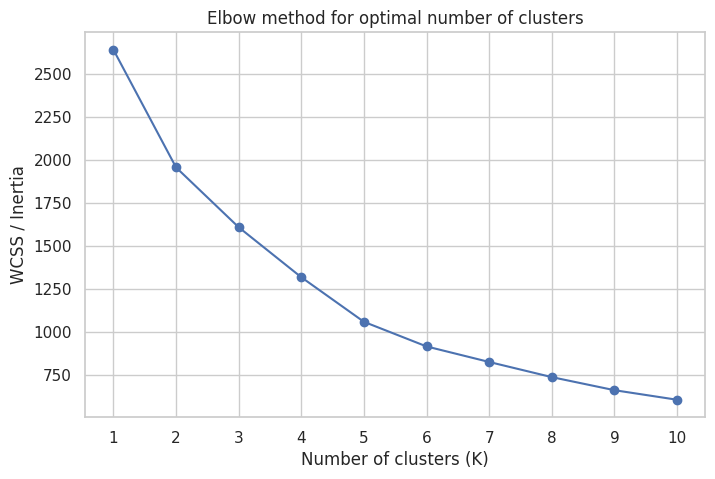

In [13]:
# Calculate WCSS (Within cluster sum of squares)
WCSS = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    WCSS.append(kmeans.inertia_)

# plot the elbow curve
plt.figure(figsize=(8,5))
plt.plot(list(k_values), WCSS, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow method for optimal number of clusters")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

In [14]:
# Calculate the silhouette scores to support the elbow decision
silhouette_values = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    score = silhouette_score(X_scaled, model.labels_)
    silhouette_values.append(score)

silhouette_table = pd.DataFrame({
    "Number of Clusters": list(range(2, 11)),
    "Silhouette Score": silhouette_values
})

display(silhouette_table.round(4))

,Number of Clusters,Silhouette Score
0,2,0.5472
1,3,0.5483
2,4,0.3485
3,5,0.3690
4,6,0.3782
5,7,0.3343
6,8,0.3201
7,9,0.3090
8,10,0.3112


In [15]:
suggested_k = int(
    silhouette_table.loc[silhouette_table["Silhouette Score"].idxmax(), "Number of Clusters"]
)

print("K suggested by the highest silhouette score:", suggested_k)

K suggested by the highest silhouette score: 3


In [16]:
K = suggested_k
kmeans_model = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans_model.fit_predict(X_scaled)

In [17]:
# add cluster labels to a copy of original dataset
df_means = df.copy()
df_means["KMeans_Cluster"] = kmeans_labels

print("K means clustering completed")
print("\nNumber of customers in each cluster")
print(df_means["KMeans_Cluster"].value_counts().sort_index())

print("\nAverage spending per K-Means cluster")
display(df_means.groupby("KMeans_Cluster")[features].mean().round(1))

K means clustering completed

Number of customers in each cluster
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Average spending per K-Means cluster


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,10440.9,19386.4,28656.1,2190.2,13327.8,2374.2
1,12062.9,4115.1,5535.0,2940.7,1696.2,1299.1
2,34782.0,30367.0,16898.0,48701.5,755.5,26776.0


## Hierarchical clustering

In [18]:
# build the model
hierarchical_model = AgglomerativeClustering(n_clusters=K, linkage="ward", metric="euclidean")
hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

In [19]:
# Store the cluster labels
df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Cluster"] = hierarchical_labels

print("Hierarchical clustering completed")
print("\nNumber of customers in each cluster")
print(df_hierarchical["Hierarchical_Cluster"].value_counts().sort_index())

Hierarchical clustering completed

Number of customers in each cluster
Hierarchical_Cluster
0      6
1    281
2    153
Name: count, dtype: int64


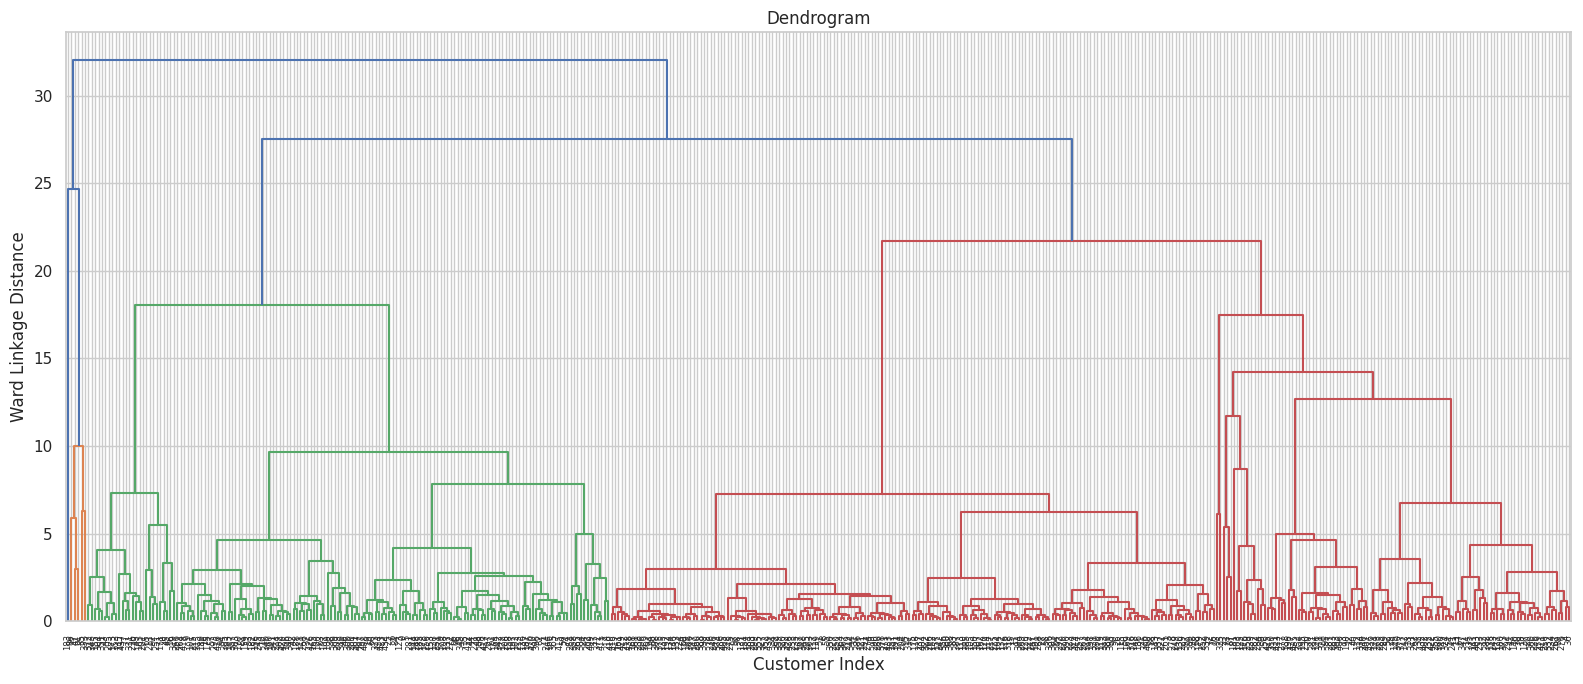

In [20]:
Z = linkage(X_scaled, method="ward", metric="euclidean")

plt.figure(figsize=(16,7))
dendrogram(Z, leaf_rotation=90, leaf_font_size=6)

plt.title("Dendrogram")
plt.xlabel("Customer Index")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

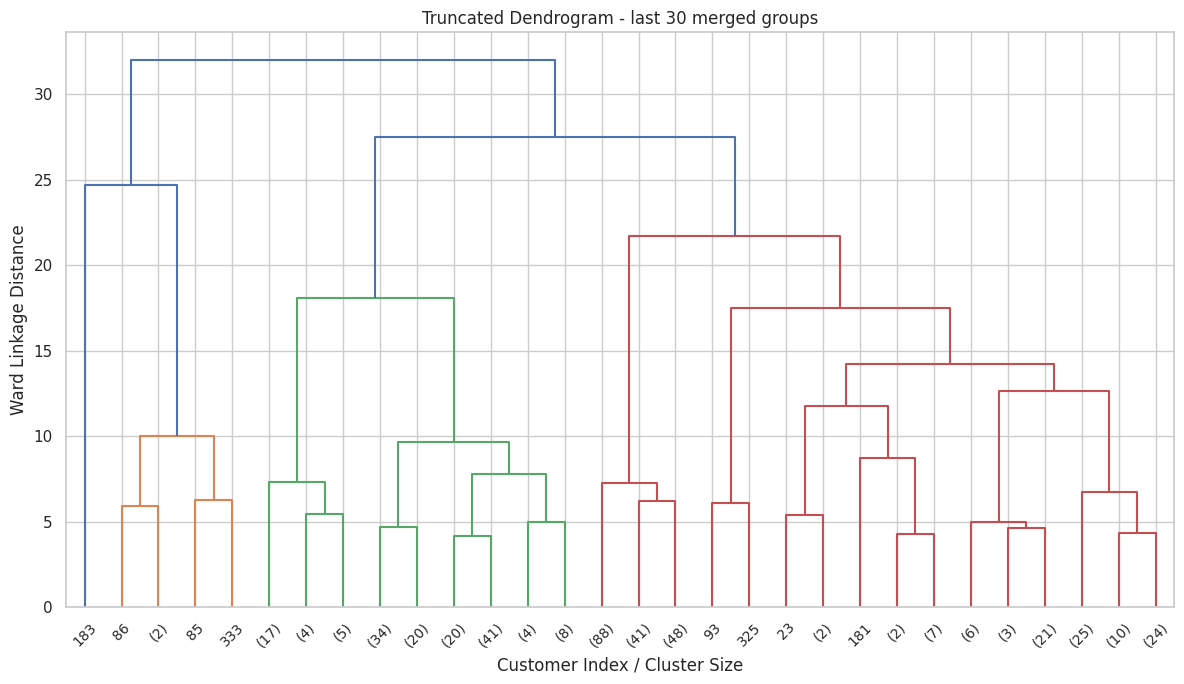

In [21]:
# Truncated dendrogram for easier interpretation
plt.figure(figsize=(12,7))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45, show_leaf_counts=True)

plt.title("Truncated Dendrogram - last 30 merged groups")
plt.xlabel("Customer Index / Cluster Size")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

In [22]:
# reduce six scaled features to two principal components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(
    "Variance explained by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# create a plotting dataframe
plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans Cluster": kmeans_labels.astype(str),
    "Hierarchical Cluster": hierarchical_labels.astype(str)
})

Variance explained by two PCA components: 72.46 %


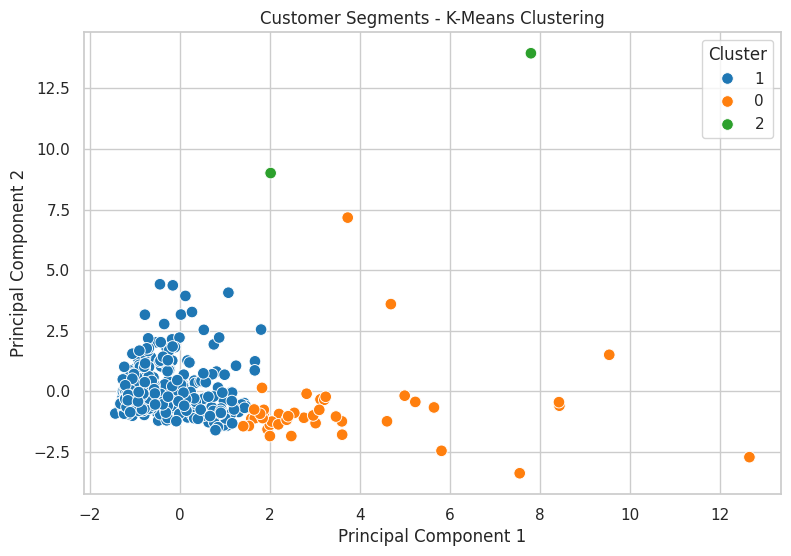

In [23]:
# k means visualisation
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="KMeans Cluster", palette="tab10", s=70)

plt.title("Customer Segments - K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Cluster")
plt.grid(True)
plt.show()

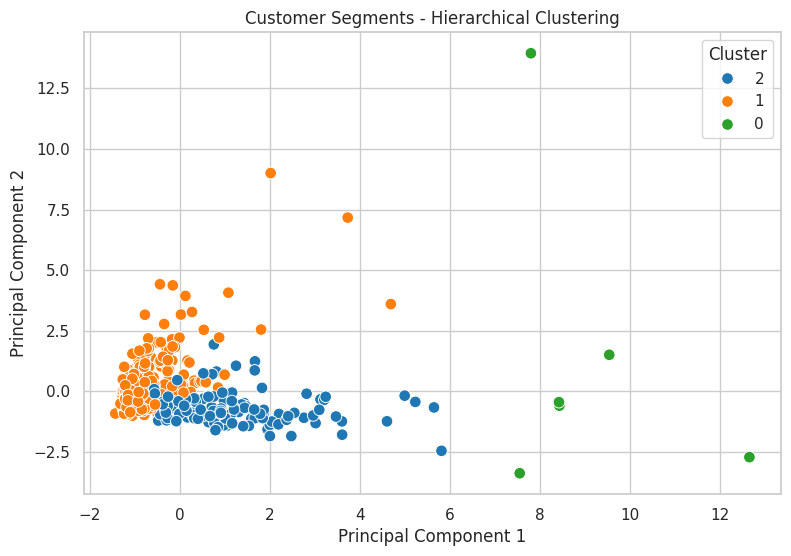

In [24]:
# hierarchical clustering visualisation
plt.figure(figsize=(9,6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Hierarchical Cluster", palette="tab10", s=70)

plt.title("Customer Segments - Hierarchical Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(title="Cluster")
plt.grid(True)
plt.show()

In [25]:
def evaluate_clustering(X_data, labels, model_name):
    return {
        "Algorithm": model_name,
        "Number of clusters": len(np.unique(labels)),
        "Silhouette Score": silhouette_score(X_data, labels)
    }

In [26]:
comparison = pd.DataFrame([
    evaluate_clustering(X_scaled, kmeans_labels, "K-Means"),
    evaluate_clustering(X_scaled, hierarchical_labels, "Hierarchical (Ward)")
])

display(comparison.round(4))

,Algorithm,Number of clusters,Silhouette Score
0,K-Means,3,0.5483
1,Hierarchical (Ward),3,0.2646
